# Elmer/Ice → pyISSM walkthrough

This notebook runs the conversion **one step at a time** (steps 0–6), using the functions in the
`elmer2pyissm` package, so you can inspect and plot the output of each step before trusting it.

* By default it runs on the **synthetic templates** (`USE_TEMPLATES = True`). Every check should pass,
  and the outputs saved in this notebook show what to expect.
* Set `USE_TEMPLATES = False` and point the paths at the real files to convert the real run.

> ⚠️ **CHECK** boxes mark decisions the group must verify against the real data or the Elmer `.sif`.
> The same points appear as `# CHECK:` comments in the code:
> `grep -rn "CHECK:" elmer2pyissm/`

In [1]:
import os, sys, warnings
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(".."))      # use the package from this repo
import elmer2pyissm
from elmer2pyissm import reader, mesh, geometry, dynamics, forcing, results, validate
import pyissm

USE_TEMPLATES = True

if USE_TEMPLATES:
    PFX = "../templates/templates/template_ssp370_c003_m005_v2"
    STATES, FORCING, SCALARS = PFX + "_states.nc", PFX + "_forcing.nc", PFX + "_scalars.nc"
    TRUTH = "../templates/templates/template_truth.json"
else:
    # Use the ORIGINAL multi-timestep files, not the cdo subsets
    DATA = "/path/to/OneDrive_1_11-14-2026"
    STATES  = f"{DATA}/ssp370_c003_m005_v2_states.nc"
    FORCING = f"{DATA}/ssp370_c003_m005_v2_forcing.nc"
    SCALARS = f"{DATA}/ssp370_c003_m005_v2_scalars.nc"
    TRUTH = None

STEP = -1          # states timestep that initialises the model (-1 = last)

## Step 0 — open the files

> ⚠️ **CHECK**
> * Times: states are snapshots (`time_instant`), while forcing and scalars are annual means whose
>   time stamp is the *centre* of the averaging interval. Check that the printed years make sense
>   for the real run.
> * `groundedmask` values should be exactly −1, 0 and 1.
> * The units of every field you use (table below). `mu`, `alphaRC` and `betaRC` have **no units
>   attribute**, so look them up in the `.sif`.

In [2]:
E = reader.ElmerOutput(STATES, FORCING, SCALARS)
print(E.summary())
step = STEP % E.states.ntimes
print("\nusing states step", step, "=", E.states.years[step])
print("forcing faces identical to states faces:", E.check_same_connectivity())
print("groundedmask values:", np.unique(E.states.var("groundedmask", step)))

states   ../templates/templates/template_ssp370_c003_m005_v2_states.nc
         times (time_instant): [2016.0, 2017.0, 2018.0, 2019.0, 2020.0]
forcing  ../templates/templates/template_ssp370_c003_m005_v2_forcing.nc
         times (time): [2015.5, 2016.5, 2017.5, 2018.5, 2019.5]
scalars  ../templates/templates/template_ssp370_c003_m005_v2_scalars.nc
         times (time): [2015.5, 2016.5, 2017.5, 2018.5, 2019.5]
mesh: 1271 nodes, 2400 faces

using states step 4 = 2020.0
forcing faces identical to states faces: True
groundedmask values: [-1.  0.  1.]


In [3]:
# Units table for the fields the converter uses
use = ["h", "zs", "zb", "bedrock", "groundedmask", "ssavelocity_x", "strbasemag", "tau_RC", "alphaRC",
       "betaRC", "ceff", "effective_pressure", "mu", "sftgif", "sftgrf", "sftflf"]
for name in use:
    print(f"{name:20s} {E.states.location(name) or '':5s} {E.states.units(name)}")
print()
for name in ["acabf", "smb_total_flux", "bmb", "libmassbf", "thermal_forcing_at_draft"]:
    print(f"{name:20s} {E.forcing.location(name) or '':5s} {E.forcing.units(name)}")

h                    node  m
zs                   node  m
zb                   node  m
bedrock              node  m
groundedmask         node  1
ssavelocity_x        node  m a-1
strbasemag           face  MPa
tau_RC               node  MPa
alphaRC              node  None
betaRC               node  None
ceff                 node  MPa m-1 a
effective_pressure   node  MPa
mu                   node  None
sftgif               face  1
sftgrf               face  1
sftflf               face  1

acabf                face  m ice a-1
smb_total_flux       face  m ice a-1
bmb                  node  m ice a-1
libmassbf            face  m ice a-1
thermal_forcing_at_draft node  degC


## Step 1 — mesh

Elmer node = ISSM vertex and Elmer face = ISSM element. The converter makes the indices 1-based,
flips clockwise triangles, and computes edges, boundary segments and element connectivity with numpy.
No ISSM build is needed.

> ⚠️ **CHECK**
> * How many triangles were flipped? Anything other than 0 or all of them is worth understanding.
> * Our edge and boundary counts should equal Elmer's.
> * Our triangle areas vs `cell_area`. A systematic offset of a few % means Elmer reports *true*
>   (ellipsoidal) areas, and `md.mesh.scale_factor` must be set.
> * ISSM's `edges` "no neighbour" marker and `elementconnectivity` column order (see `mesh.py`).

[mesh] 1271 vertices, 2400 elements, 3670 edges
[mesh] flipped 740 clockwise elements to CCW
[mesh] 140 boundary edges (Elmer says 140); edges: ours 3670 vs Elmer 3670
[mesh] max relative area difference vs cell_area: 2.68e-05


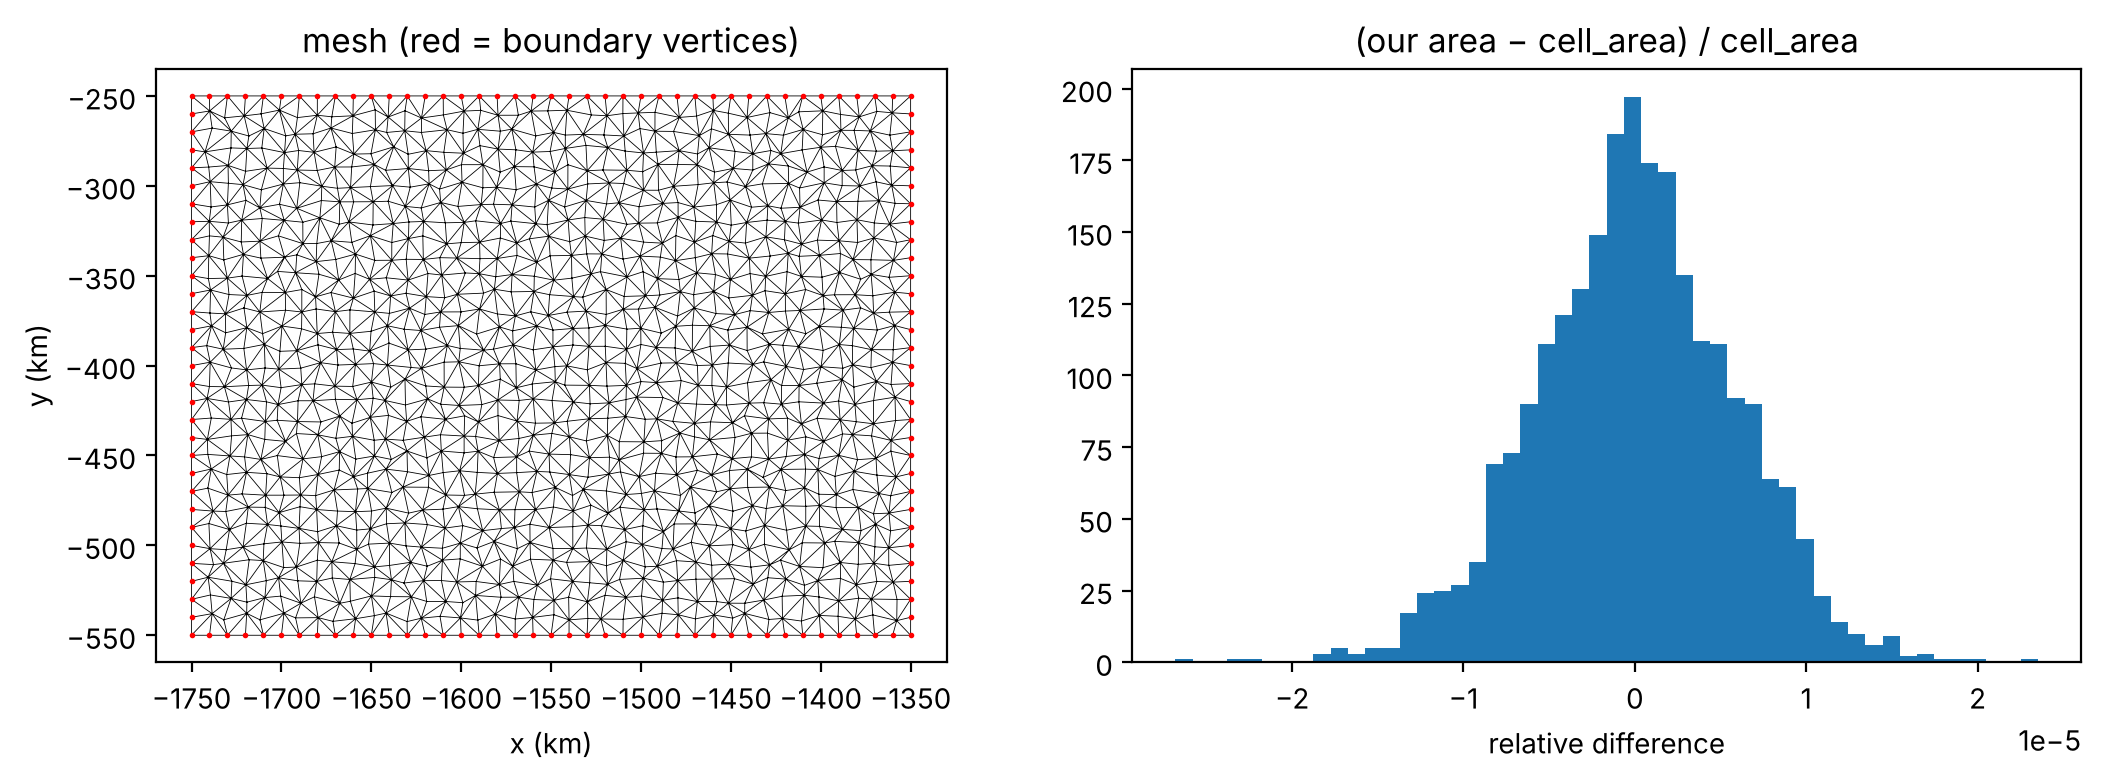

In [4]:
md_mesh, info = mesh.build_mesh(E)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].triplot(md_mesh.x / 1e3, md_mesh.y / 1e3, md_mesh.elements - 1, lw=0.3, color="k")
ax[0].plot(md_mesh.x[md_mesh.vertexonboundary == 1] / 1e3, md_mesh.y[md_mesh.vertexonboundary == 1] / 1e3, "r.", ms=2)
ax[0].set(title="mesh (red = boundary vertices)", xlabel="x (km)", ylabel="y (km)", aspect="equal")
ca = E.states.var("cell_area")
ax[1].hist((info["areas"] - ca) / ca, bins=50)
ax[1].set(title="(our area − cell_area) / cell_area", xlabel="relative difference")
plt.tight_layout()

## Step 2 — geometry and masks

> ⚠️ **CHECK**
> * `geometry.MIN_THICKNESS`: Elmer's minimum thickness from the `.sif`. The default 1 m is a guess.
> * Densities: pyISSM defaults to `rho_water = 1023`, and Elmer Antarctic setups often use 1028.
>   Set `convert.RHO_ICE / RHO_WATER` to the `.sif` values.
> * `ocean_levelset` is Elmer's 1/0/−1 mask, not a signed distance. That's fine for plots and
>   analysis, but reinitialise it before running ISSM with grounding-line migration.

In [5]:
rho_i, rho_w = elmer2pyissm.convert.RHO_ICE, elmer2pyissm.convert.RHO_WATER
md_geom = geometry.build_geometry(E, step)
md_mask, has_ice = geometry.build_mask(E, step, md_geom, rho_i, rho_w)
floating = md_mask.ocean_levelset < 0

[geometry] step 4: max |surface - base - thickness| = 4.547e-13 m
[mask] step 4: grounded 934, GL 33, floating 304, with ice 1023
[mask] nodes where groundedmask disagrees with flotation: 0


## Step 3 — velocity, friction, rheology

The default friction method `invert` fixes `m` and `u0` and solves ISSM's regularised-Coulomb law
for `C`, so ISSM reproduces Elmer's `strbasemag` at this snapshot. That works whatever Elmer's exact
parameterisation is.

> ⚠️ **CHECK**
> * What Elmer's `tau_RC`, `alphaRC`, `betaRC` and `ceff` mean. The `params` method assumes the
>   template's placeholder law. Confirm the law from the `.sif` and the Elmer/Ice source before using it.
> * `u0` and `m`: ISSM's `u0` is a single scalar.
> * `mu` → `rheology_B`: units (MPa a^1/3?), the factor 2^(1/n), and whether `mu` is the Glen
>   parameter or the effective viscosity (see `dynamics.build_rheology_B`).
> * `dynamics.YTS_ELMER` must equal the year length in the `.sif`.

[init] step 4: max speed 1551.3 m/a
[friction] regcoulomb (invert): m = 3, u0 = 300 m/a, C median (grounded) = 2.98e+03 SI
[friction] tau_b ISSM vs Elmer strbasemag: median rel err 2.14e-03, 95th pct 3.49e-02
[rheology] B from mu: median 1.99e+08 Pa s^(1/3) (typical ice: 0.5e8 - 2.5e8)


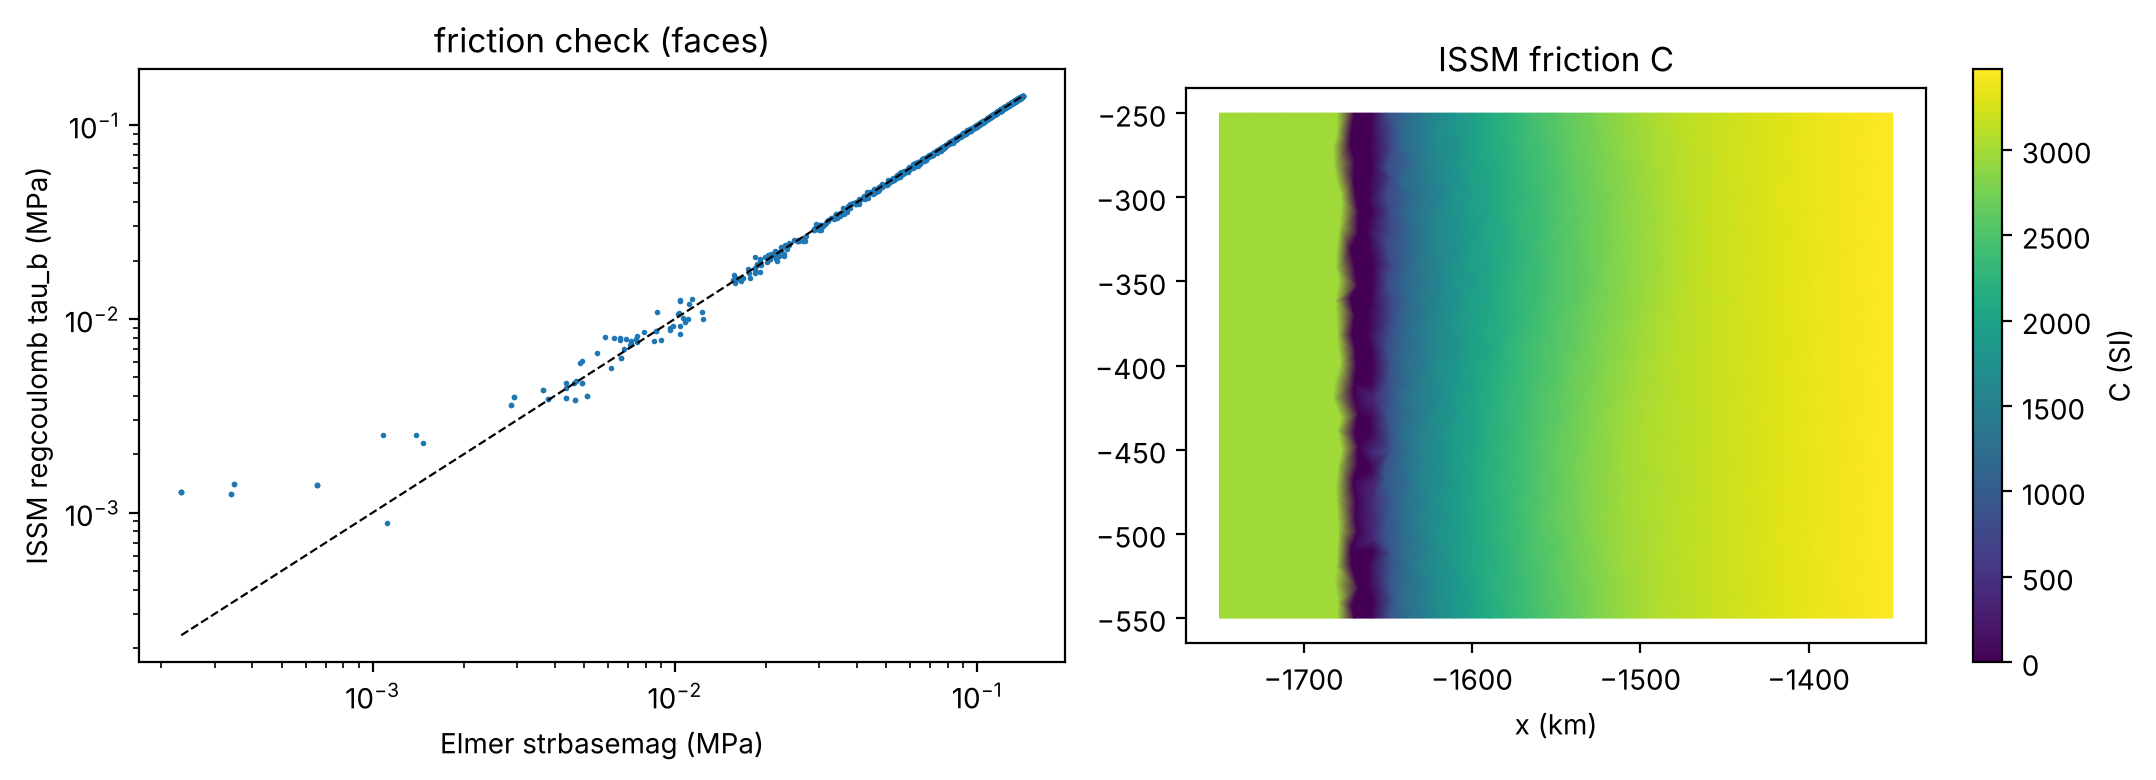

In [6]:
md_init = dynamics.build_initialization(E, step)
md_fric, fdiag = dynamics.build_friction(E, step, info, has_ice, floating, method="invert")
B = dynamics.build_rheology_B(E, step)

tau_e = E.states.var("strbasemag", step)
sel = tau_e > 1e-4
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(tau_e[sel], fdiag["taub_issm_face_MPa"][sel], ".", ms=2)
lim = [tau_e[sel].min(), tau_e[sel].max()]
ax[0].plot(lim, lim, "k--", lw=0.8)
ax[0].set(xlabel="Elmer strbasemag (MPa)", ylabel="ISSM regcoulomb tau_b (MPa)", title="friction check (faces)")
tc = ax[1].tripcolor(md_mesh.x / 1e3, md_mesh.y / 1e3, md_mesh.elements - 1, md_fric.C, shading="gouraud")
plt.colorbar(tc, ax=ax[1], label="C (SI)")
ax[1].set(title="ISSM friction C", aspect="equal", xlabel="x (km)")
plt.tight_layout()

## Step 4 — SMB and basal melt

> ⚠️ **CHECK**
> * Which SMB field the ice model actually used: `acabf`, `smb_total_flux` or `acabf_forcing`.
> * Melt sign: ISSM wants melt **positive**. The plot on the right should lie on the 1:1 line if
>   `bmb` is melt-positive and `libmassbf` is melt-negative.
> * Which forcing record goes with which snapshot (annual mean vs 1 January snapshot).

[smb] acabf: range 0.000 .. 0.585 m ice/a
[basal] floating melt: range 0.000 .. 5.311 m ice/a


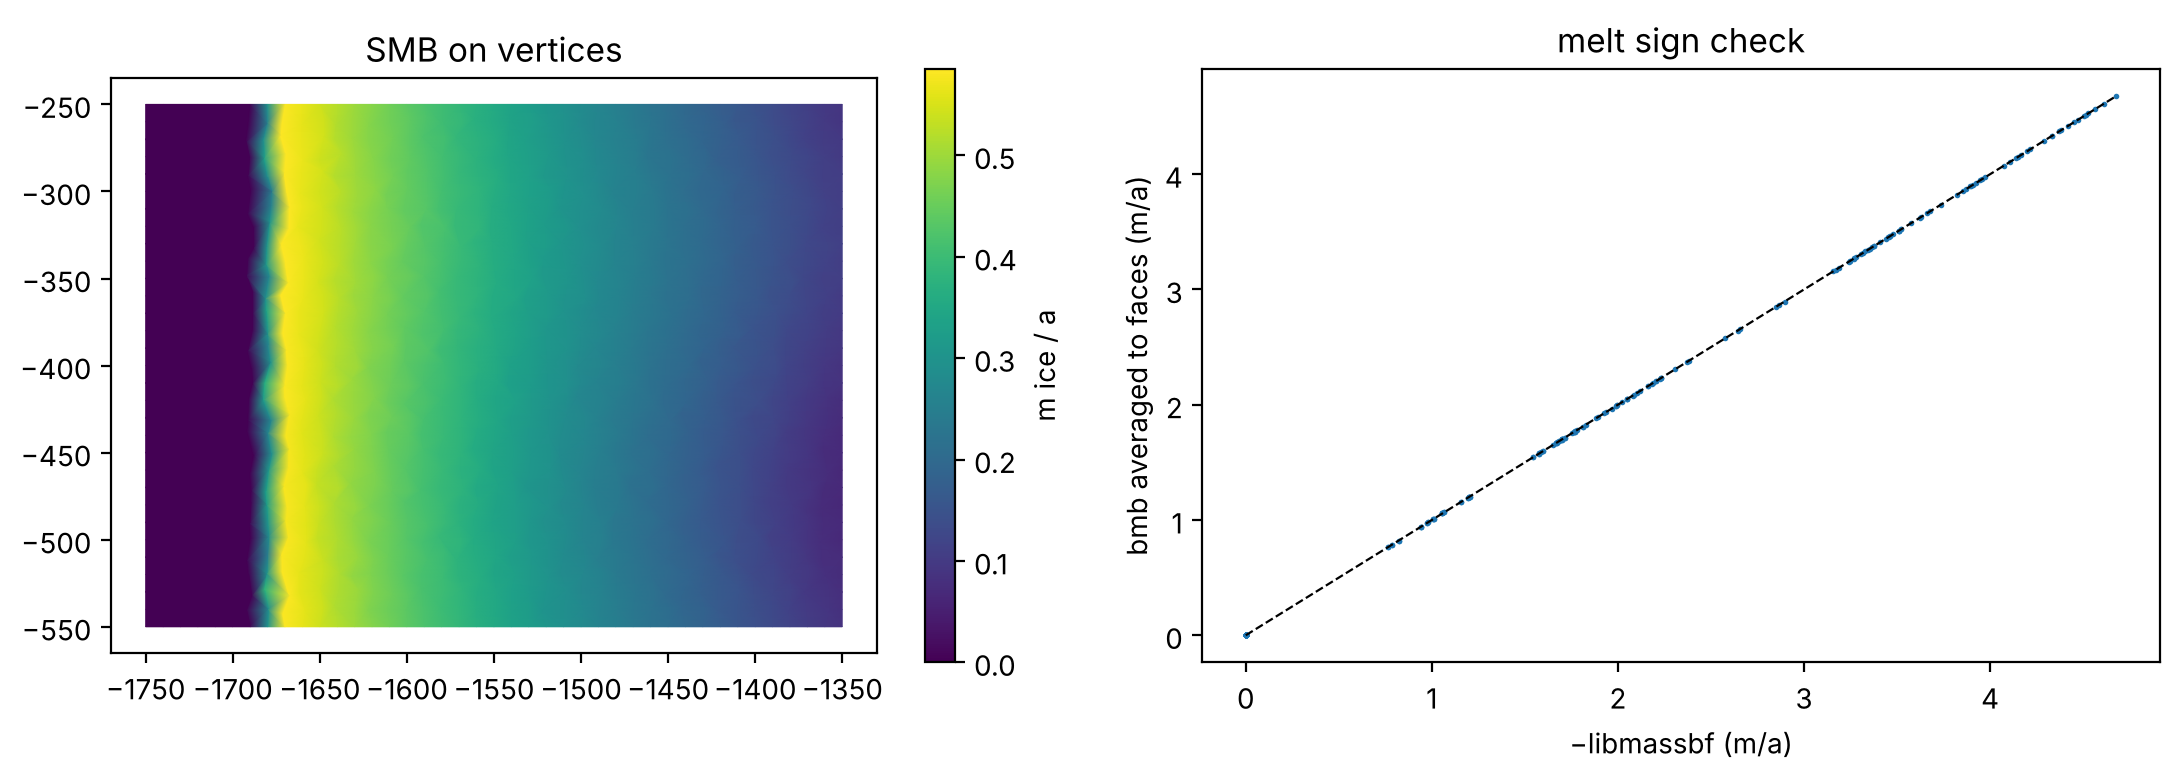

In [7]:
md_smb = forcing.build_smb(E, step, info)
md_bf = forcing.build_basalforcings(E, step, info, floating)

el0, areas = info["elements0"], info["areas"]
melt_face_from_bmb = mesh.node_to_face(md_bf.floatingice_melting_rate, el0)
lib = E.forcing.var("libmassbf", step)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tc = ax[0].tripcolor(md_mesh.x / 1e3, md_mesh.y / 1e3, md_mesh.elements - 1, md_smb.mass_balance, shading="gouraud")
plt.colorbar(tc, ax=ax[0], label="m ice / a"); ax[0].set(title="SMB on vertices", aspect="equal")
ax[1].plot(-lib, melt_face_from_bmb, ".", ms=2); ax[1].plot([0, lib.min() * -1], [0, lib.min() * -1], "k--", lw=0.8)
ax[1].set(xlabel="−libmassbf (m/a)", ylabel="bmb averaged to faces (m/a)", title="melt sign check")
plt.tight_layout()

## Step 5 — results time series

Every Elmer snapshot becomes one `solutionstep` with ISSM field names, so pyISSM's tools work on
`md.results.TransientSolution` as they would for a real ISSM run. Fields only Elmer has keep the
prefix `Elmer` (`ElmerStrbasemag`, `ElmerEffectivePressure`, …).

> ⚠️ **CHECK**
> * ISSM units: `TotalSmb` and `TotalFloatingBmb` in Gt/yr, volumes in m³, areas in m².
> * `IceVolumeAboveFloatation` and `GroundedArea` use Elmer's grounded *fraction* per face, not
>   ISSM's sub-element grounding-line scheme.

In [8]:
TS = results.build_transient_results(E, info, rho_i, rho_w)

[results] TransientSolution with 5 steps: [2016.0, 2017.0, 2018.0, 2019.0, 2020.0]


## Step 6 — assemble, validate, save

This puts the pieces into one `pyissm.model.Model()`, the same way `convert.elmer_to_pyissm` does,
then checks the result against Elmer's scalars file (and the template truth file, when running on
the templates).

In [9]:
md = pyissm.model.Model()
md.miscellaneous.name = E.states.global_attrs().get("model_case", "elmer_run")
md.miscellaneous.notes = forcing.forcing_notes(E)
md.constants.yts = dynamics.YTS_ELMER
md.materials.rho_ice, md.materials.rho_water = rho_i, rho_w
md.mesh, md.geometry, md.mask = md_mesh, md_geom, md_mask
md.initialization, md.friction = md_init, md_fric
md.materials.rheology_B = B
md.materials.rheology_n = 3.0 * np.ones(md.mesh.numberofelements)
md.smb, md.basalforcings = md_smb, md_bf
md.results.TransientSolution = TS

report = {"step": step, "mesh_info": info, "friction_diag": fdiag, "elmer": E}
rows = validate(md, E, report, truth_json=TRUTH)


check                                                                ours      reference   rel err  status
----------------------------------------------------------------------------------------------------------
elements are 1-based                                                    1              1  0.00e+00  PASS
all elements CCW                                                     2400           2400  0.00e+00  PASS
boundary edges vs Elmer                                               140            140  0.00e+00  PASS
edge count vs Elmer                                                  3670           3670  0.00e+00  PASS
total area vs scalars domain_area                                 1.2e+11        1.2e+11  3.41e-08  PASS
max |s - b - H| [m]                                           4.54747e-13              0  4.55e-13  PASS
tau_b ISSM vs strbasemag (median rel)                          0.00213761              0  2.14e-03  PASS
[2016.00] IceVolume (all faces) vs scalars volume 

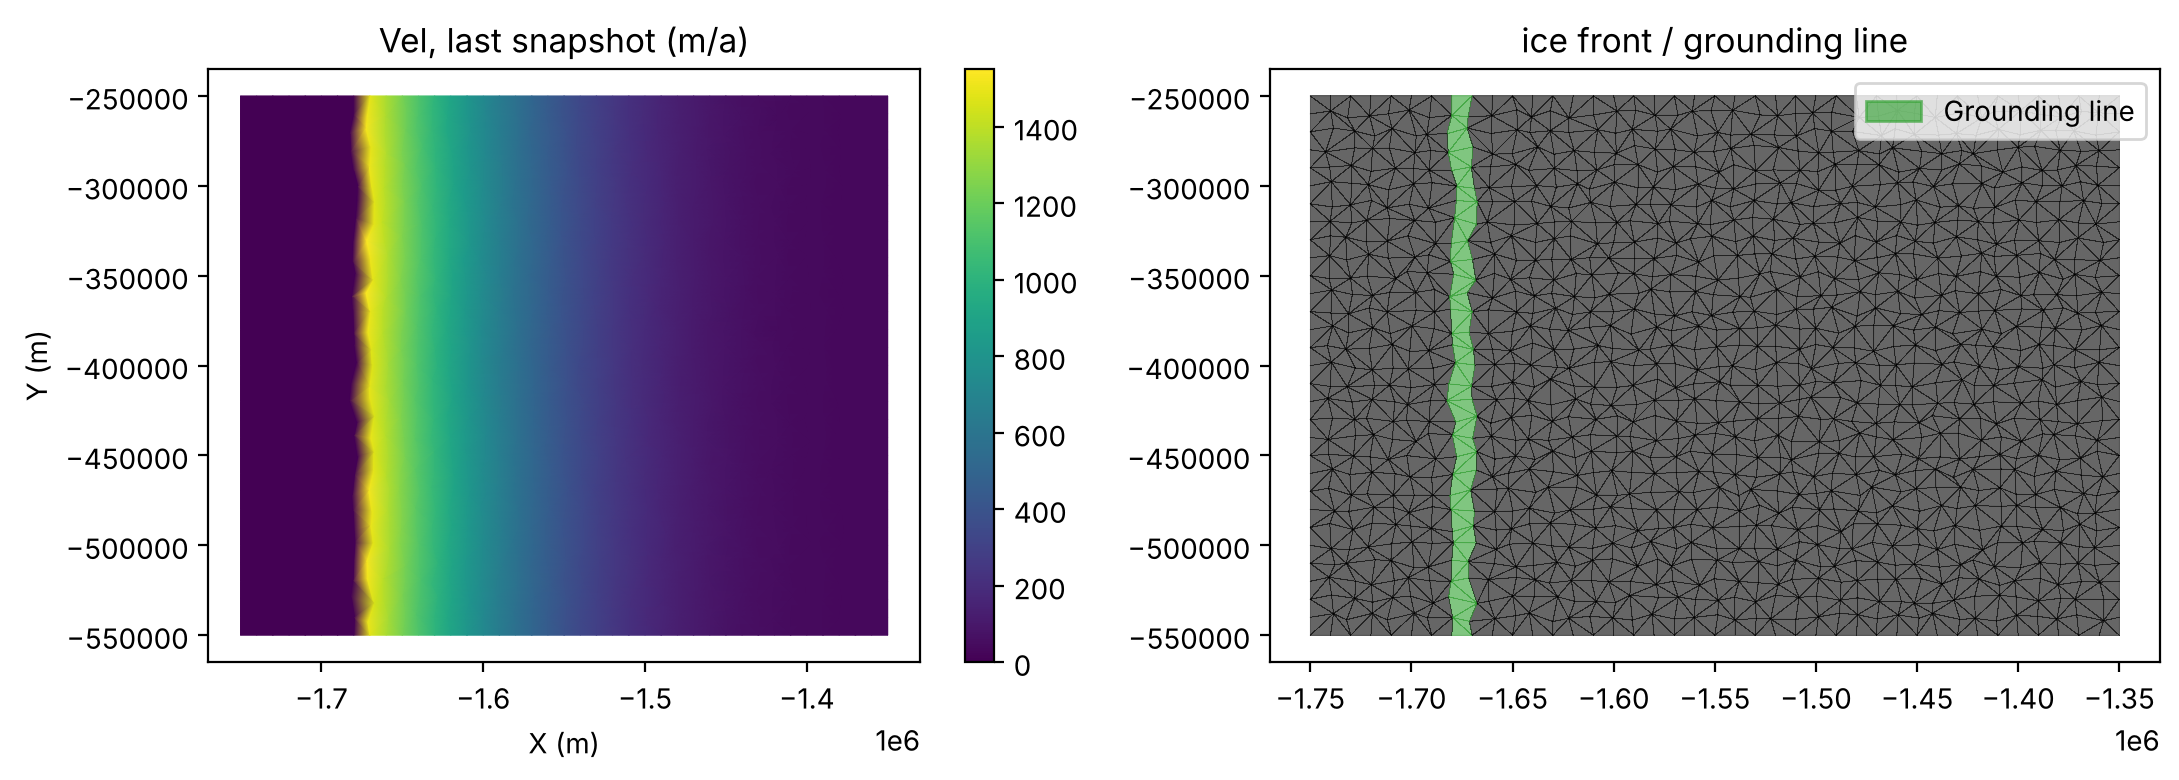

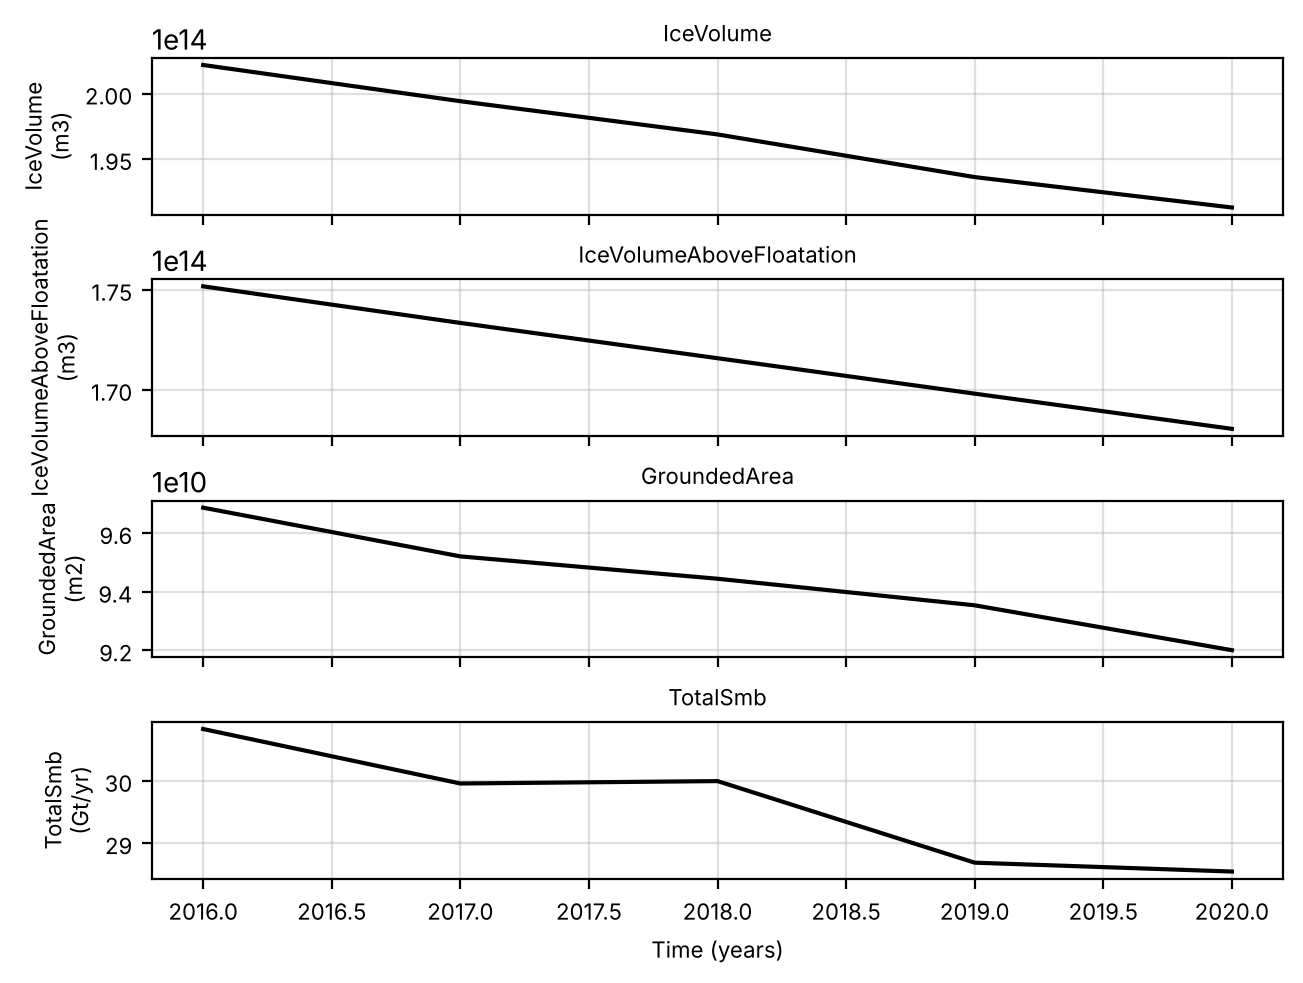

In [10]:
# pyISSM's own tools on the converted model
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
pyissm.plot.plot_model_field(md, md.results.TransientSolution.Vel[-1], ax=ax[0], show_cbar=True)
ax[0].set_title("Vel, last snapshot (m/a)")
pyissm.plot.plot_icefront(md, ax=ax[1]); ax[1].set_title("ice front / grounding line")
plt.tight_layout()

pyissm.plot.plot_model_ts(md, data_list=[TS.IceVolume, TS.IceVolumeAboveFloatation, TS.GroundedArea, TS.TotalSmb],
                          variable_list=["IceVolume", "IceVolumeAboveFloatation", "GroundedArea", "TotalSmb"],
                          unit_list=["m3", "m3", "m2", "Gt/yr"]);

In [11]:
OUT = "converted_model.nc"
pyissm.model.io.save_model(md, OUT)
md2 = pyissm.model.io.load_model(OUT)
print("round trip IceVolume:", md2.results.TransientSolution.IceVolume)

ℹ️ Processing results group: TransientSolution
round trip IceVolume: [2.02193356e+14 1.99424042e+14 1.96884445e+14 1.93623465e+14
 1.91299170e+14]


## Before using the real files: the full CHECK list

```bash
grep -rn "CHECK:" elmer2pyissm/
```

| # | What to confirm | Where |
|---|---|---|
| 1 | time stamps and bounds of forcing/scalars (centre of interval?) | `reader.py`, `results.py` |
| 2 | forcing faces in the same order as states | `convert.py` (printed) |
| 3 | number of clockwise triangles flipped | `mesh.py` |
| 4 | projected vs true area (`scale_factor`) | `mesh.py`, step 6 volume check |
| 5 | ISSM `edges` / `elementconnectivity` conventions (only matters before solving) | `mesh.py` |
| 6 | minimum thickness | `geometry.MIN_THICKNESS` |
| 7 | densities and year length | `convert.RHO_*`, `dynamics.YTS_ELMER` |
| 8 | groundedmask convention; signed-distance levelset for solving | `geometry.py` |
| 9 | Elmer friction law, and the meaning of `tau_RC`, `alphaRC`, `betaRC`, `ceff` | `dynamics.build_friction` |
| 10 | `mu` units and definition → `rheology_B` | `dynamics.build_rheology_B` |
| 11 | which SMB field; melt sign; forcing/snapshot pairing | `forcing.py`, `results.py` |
| 12 | volume definition (all faces vs ice only) | step 6 output |
